# Assignment 4: Time Series Classification Part 2


Name: *Pratham Aggarwal* | Github: *prathamaeron* | USC ID: *1537722913*


# Code from Assignment 3

## Importing the Libraries


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.feature_selection import f_classif


## (a) Loading Data and (b) Train/Test Split

In [2]:
data_dir = Path("../data")
activity_folders = sorted([p for p in data_dir.iterdir() if p.is_dir()])
series_columns = [
    "avg_rss12", "var_rss12",
    "avg_rss13", "var_rss13",
    "avg_rss23", "var_rss23",
]


def build_feature_frame(files):
    rows = []
    for csv_file in sorted(files):
        activity = csv_file.parent.name
        df = pd.read_csv(
            csv_file,
            comment="#",
            sep=r"[,\s]+",
            engine="python",
            header=None,
            on_bad_lines="skip",
            dtype=str,
        )

        if df.shape[1] < 7:
            continue

        df = df.iloc[:, :7].copy()
        df.columns = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

        row = {"activity": activity, "instance": csv_file.stem}

        for series in series_columns:
            values = pd.to_numeric(df[series], errors="coerce")
            row[f"{series}_min"] = values.min()
            row[f"{series}_max"] = values.max()
            row[f"{series}_mean"] = values.mean()
            row[f"{series}_median"] = values.median()
            row[f"{series}_std"] = values.std(ddof=1)
            row[f"{series}_q1"] = values.quantile(0.25)
            row[f"{series}_q3"] = values.quantile(0.75)

        rows.append(row)

    return pd.DataFrame(rows)


train_files = []
test_files = []

for folder in activity_folders:
    files = sorted(folder.glob("dataset*.csv"))
    for csv_file in files:
        dataset_number = int(csv_file.stem.replace("dataset", ""))
        if folder.name in {"bending1", "bending2"}:
            is_test = dataset_number in {1, 2}
        else:
            is_test = dataset_number in {1, 2, 3}
        if is_test:
            test_files.append(csv_file)
        else:
            train_files.append(csv_file)

all_features = build_feature_frame(train_files + test_files)
train_df = build_feature_frame(train_files)
test_df = build_feature_frame(test_files)

print(f"Training instances: {len(train_df)}")
print(f"Test instances: {len(test_df)}")
print(f"Total instances: {len(all_features)}")
print(all_features.head().to_string(index=False))


Training instances: 69
Test instances: 19
Total instances: 88
activity instance  avg_rss12_min  avg_rss12_max  avg_rss12_mean  avg_rss12_median  avg_rss12_std  avg_rss12_q1  avg_rss12_q3  var_rss12_min  var_rss12_max  var_rss12_mean  var_rss12_median  var_rss12_std  var_rss12_q1  var_rss12_q3  avg_rss13_min  avg_rss13_max  avg_rss13_mean  avg_rss13_median  avg_rss13_std  avg_rss13_q1  avg_rss13_q3  var_rss13_min  var_rss13_max  var_rss13_mean  var_rss13_median  var_rss13_std  var_rss13_q1  var_rss13_q3  avg_rss23_min  avg_rss23_max  avg_rss23_mean  avg_rss23_median  avg_rss23_std  avg_rss23_q1  avg_rss23_q3  var_rss23_min  var_rss23_max  var_rss23_mean  var_rss23_median  var_rss23_std  var_rss23_q1  var_rss23_q3
bending1 dataset1          37.25          45.00       40.624792             40.50       1.476967         39.25         42.00            0.0           1.30        0.358604              0.43       0.322605          0.00          0.50            4.0          29.50       19.040937 

## (c) Feature Extraction

### (c) i. Research

Common time domain features used in time series classification include basic statistics like the minimum, maximum, mean, median, standard deviation, variance, range, skewness, kurtosis, and percentiles (Barandas et al.). People also often use features that measure the size or energy of the signal, such as root mean square (RMS), mean absolute value, total energy, and peak-to-peak distance (Phinyomark et al.). Other popular features describe how the signal changes over time, like the slope, the average difference between neighbouring points, the number of peaks, and the zero-crossing rate (Barandas et al.; Phinyomark et al.). Some more advanced options include autocorrelation and entropy, and tools like tsfresh and catch22 can calculate many of these features automatically (Christ et al.; Lubba et al.).

Works Cited

Barandas, Marília, et al. “TSFEL: Time Series Feature Extraction Library.” SoftwareX, vol. 11, 2020, article 100456, https://doi.org/10.1016/j.softx.2020.100456.

Christ, Maximilian, et al. “Time Series FeatuRe Extraction on Basis of Scalable Hypothesis Tests (tsfresh – A Python Package).” Neurocomputing, vol. 307, 2018, pp. 72–77, https://doi.org/10.1016/j.neucom.2018.03.067.

Lubba, Carl H., et al. “catch22: CAnonical Time-Series CHaracteristics.” Data Mining and Knowledge Discovery, vol. 33, no. 6, 2019, pp. 1821–52, https://doi.org/10.1007/s10618-019-00647-x.

Phinyomark, Angkoon, et al. “Feature Reduction and Selection for EMG Signal Classification.” Expert Systems with Applications, vol. 39, no. 8, 2012, pp. 7420–31, https://doi.org/10.1016/j.eswa.2012.01.102.

### (c) ii. Time-Domain Features

For each instance, I calculate seven statistics for each of the six sensor series: minimum, maximum, mean, median, sample standard deviation, first quartile, and third quartile. This produces 42 features per instance.

In [3]:
feature_columns = [col for col in all_features.columns if col not in {"activity", "instance"}]
feature_summary = all_features[feature_columns].describe().T
feature_summary[["mean", "std", "min", "50%", "max"]].round(4)


,mean,std,min,50%,max
avg_rss12_min,29.0367,9.5700,0.0000,28.6250,48.0000
avg_rss12_max,45.4731,4.3944,30.0000,45.7500,56.2500
avg_rss12_mean,38.9174,5.3357,24.5630,39.4338,48.0042
avg_rss12_median,38.8567,5.4401,24.2500,39.4150,48.0000
avg_rss12_std,2.9890,1.7722,0.0320,3.2127,7.6841
avg_rss12_q1,37.0193,6.1539,23.1875,39.2000,48.0000
avg_rss12_q3,41.1972,5.1389,26.5000,40.2500,54.0000
var_rss12_min,0.0000,0.0000,0.0000,0.0000,0.0000
var_rss12_max,6.2901,5.0627,0.4300,4.5000,17.2400
var_rss12_mean,1.4592,1.5742,0.0072,0.4894,4.5766


### (c) iii. Bootstrap Confidence Intervals

For each feature, I draw 2,000 bootstrap samples with replacement and calculate the sample standard deviation. The 5th and 95th percentiles give a 90% percentile confidence interval.

In [4]:
rng = np.random.default_rng(42)
bootstrap_results = []

for feature in feature_columns:
    values = all_features[feature].dropna().to_numpy()
    base_std = values.std(ddof=1)
    boot_str = np.empty(2000)

    for i in range(2000):
        sample = rng.choice(values, size=len(values), replace=True)
        boot_str[i] = sample.std(ddof=1)

    lower, upper = np.quantile(boot_str, [0.05, 0.95])
    bootstrap_results.append({
        "Feature": feature,
        "Std Dev": base_std,
        "90% CI Lower": lower,
        "90% CI Upper": upper,
    })

bootstrap_table = pd.DataFrame(bootstrap_results).sort_values("Std Dev", ascending=False)
bootstrap_table.round(4)

,Feature,Std Dev,90% CI Lower,90% CI Upper
0,avg_rss12_min,9.5700,8.2270,10.7828
5,avg_rss12_q1,6.1539,5.5854,6.6367
28,avg_rss23_min,6.1240,4.3957,7.4622
33,avg_rss23_q1,6.0965,4.9026,7.1967
31,avg_rss23_median,5.8138,4.5207,6.9229
29,avg_rss23_max,5.7412,4.7594,6.5348
30,avg_rss23_mean,5.6755,4.4077,6.8186
34,avg_rss23_q3,5.5317,4.3897,6.4906
3,avg_rss12_median,5.4401,4.8343,6.0051
2,avg_rss12_mean,5.3357,4.6963,5.9058


I rank training-set features by their one-way ANOVA F-statistic across activity labels and report the top three. Constant features are excluded because they cannot distinguish between activities.

In [5]:
X = train_df[feature_columns]
y = train_df["activity"]

non_constant_features = X.columns[X.nunique(dropna=False) > 1]
X = X[non_constant_features]
f_values, p_values = f_classif(X, y)
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "F-statistic": f_values,
    "p-value": p_values,
}).sort_values("F-statistic", ascending=False)

selected_features = feature_importance.head(3)
selected_features.round(6)

,Feature,F-statistic,p-value
8,var_rss12_mean,901.301852,0.0
12,var_rss12_q3,810.830665,0.0
22,var_rss13_median,795.840520,0.0


# Assignment 4 continued

## (a) Binary classification using logistic regression

I use minimum, mean, and maximum as the three time-domain feature types, as suggested in Question 1(c)(iv), and plot them for sensor series 1, 2, and 6. For the binary task, both bending activities form the positive class.

In [6]:
import matplotlib.pyplot as plt
import statsmodels.api as sm
import warnings
from scipy.special import expit
from sklearn.base import clone
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, label_binarize
from statsmodels.tools.sm_exceptions import PerfectSeparationWarning
# Cache the six raw sensor series once so each segment count uses identical samples.
raw_series_by_file = {}
for csv_file in train_files + test_files:
    raw_df = pd.read_csv(
        csv_file,
        comment="#",
        sep=r"[,\s]+",
        engine="python",
        header=None,
        on_bad_lines="skip",
        dtype=str,
    )
    sensor_values = raw_df.iloc[:, 1:7].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
    if sensor_values.shape[1] != 6 or sensor_values.shape[0] < 20:
        raise ValueError(f"Unexpected sensor data shape in {csv_file}: {sensor_values.shape}")
    if not np.isfinite(sensor_values).all():
        raise ValueError(f"Non-finite sensor value in {csv_file}")
    raw_series_by_file[csv_file] = sensor_values

segment_statistics = ["min", "max", "mean", "median", "std", "q1", "q3"]

def build_segment_frame(files, n_segments):
    rows = []
    for csv_file in files:
        activity = csv_file.parent.name
        row = {"activity": activity, "instance": csv_file.stem}
        segments = np.array_split(raw_series_by_file[csv_file], n_segments, axis=0)
        for segment_index, segment in enumerate(segments, start=1):
            for sensor_index, series_name in enumerate(series_columns):
                values = segment[:, sensor_index]
                statistics = {
                    "min": np.min(values),
                    "max": np.max(values),
                    "mean": np.mean(values),
                    "median": np.median(values),
                    "std": np.std(values, ddof=1),
                    "q1": np.quantile(values, 0.25),
                    "q3": np.quantile(values, 0.75),
                }
                for statistic, value in statistics.items():
                    row[f"{series_name}_{statistic}_seg{segment_index}"] = value
        rows.append(row)
    return pd.DataFrame(rows)

segment_frame_cache = {}
def get_segment_frames(n_segments):
    if n_segments not in segment_frame_cache:
        segment_frame_cache[n_segments] = (
            build_segment_frame(train_files, n_segments),
            build_segment_frame(test_files, n_segments),
        )
    return segment_frame_cache[n_segments]

binary_train = get_segment_frames(1)[0].copy()
binary_train["is_bending"] = binary_train["activity"].isin(["bending1", "bending2"]).astype(int)
print("Training class counts (0 = other, 1 = bending):")
print(binary_train["is_bending"].value_counts().sort_index())

Training class counts (0 = other, 1 = bending):
is_bending
0    60
1     9
Name: count, dtype: int64


### (a)(i) Scatter plots using the complete training series

Each 3-D plot shows one of the selected summary statistics, with its three axes corresponding to sensor series 1, 2, and 6. Points are colored by bending versus other activity.

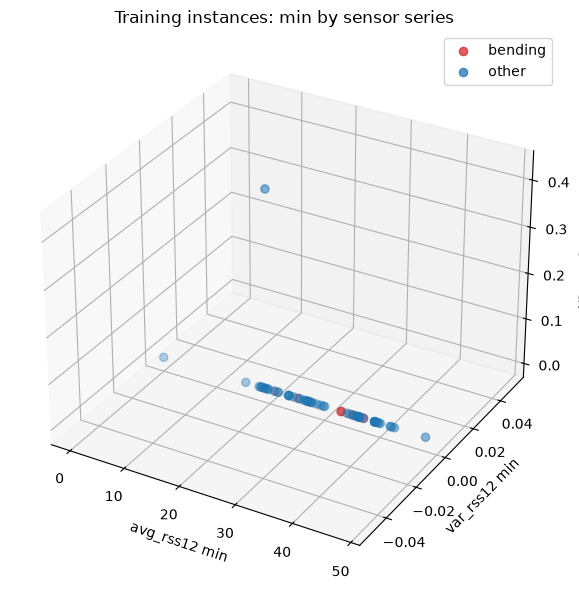

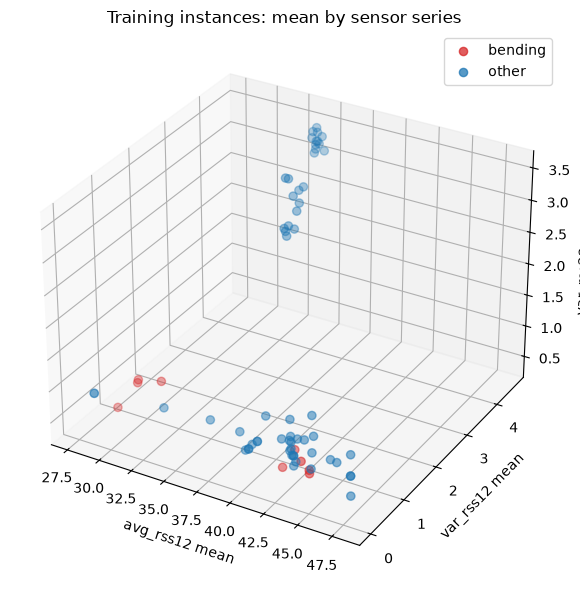

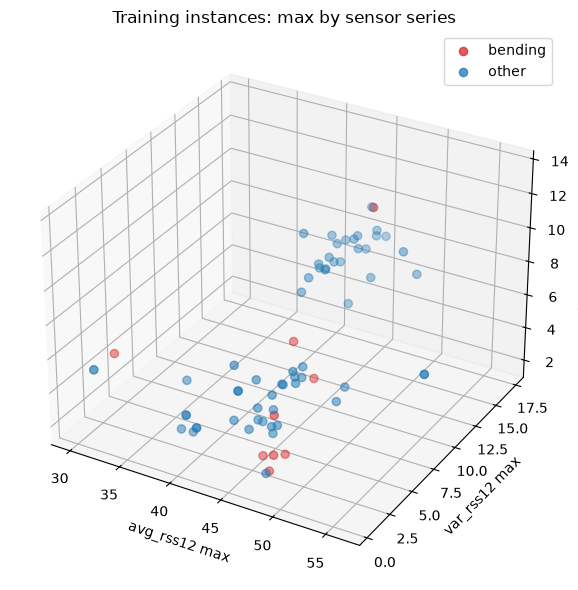

In [7]:
selected_statistics = ["min", "mean", "max"]
selected_sensor_indices = [0, 1, 5]
selected_sensor_names = [series_columns[index] for index in selected_sensor_indices]

for statistic in selected_statistics:
    columns = [f"{sensor}_{statistic}_seg1" for sensor in selected_sensor_names]
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")
    for label, color, description in [(1, "tab:red", "bending"), (0, "tab:blue", "other")]:
        subset = binary_train.loc[binary_train["is_bending"] == label]
        ax.scatter(
            subset[columns[0]], subset[columns[1]], subset[columns[2]],
            color=color, alpha=0.75, s=35, label=description,
        )
    ax.set_xlabel(f"{selected_sensor_names[0]} {statistic}")
    ax.set_ylabel(f"{selected_sensor_names[1]} {statistic}")
    ax.set_zlabel(f"{selected_sensor_names[2]} {statistic}")
    ax.set_title(f"Training instances: {statistic} by sensor series")
    ax.legend()
    plt.tight_layout()
    plt.show()

### (a)(ii) Scatter plots using the two half-series

The 480-observation series are divided into two contiguous, approximately equal halves. The same three-dimensional plots are repeated separately for each half. Comparing these with the complete-series plots shows whether the bending/other pattern is consistent through time or whether it depends on the part of the activity being observed. The two halves remain features of one instance; they are not treated as additional independent labeled observations. The standardized centroid distances below provide a compact descriptive comparison; they do not replace inspection of the plotted within-class spread. On this split, the mean-feature distances are similar for the full series and both halves, while maximum-feature separation is stronger in the second half and minimum-feature separation stays weak. Thus, there is no uniform large change, though some features vary by time window.

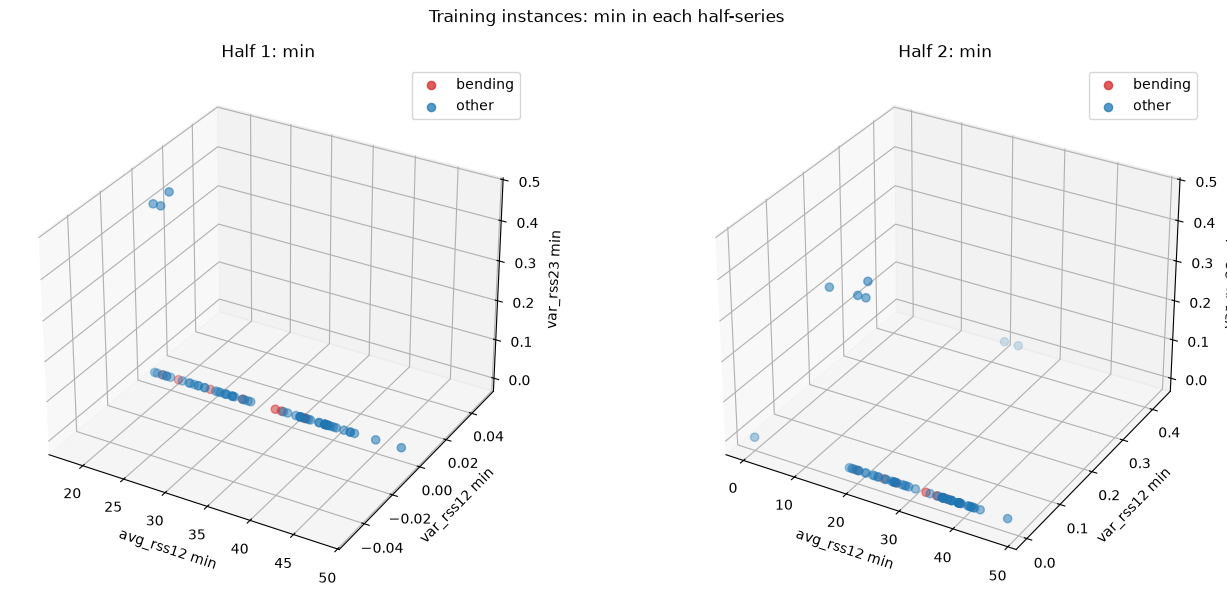

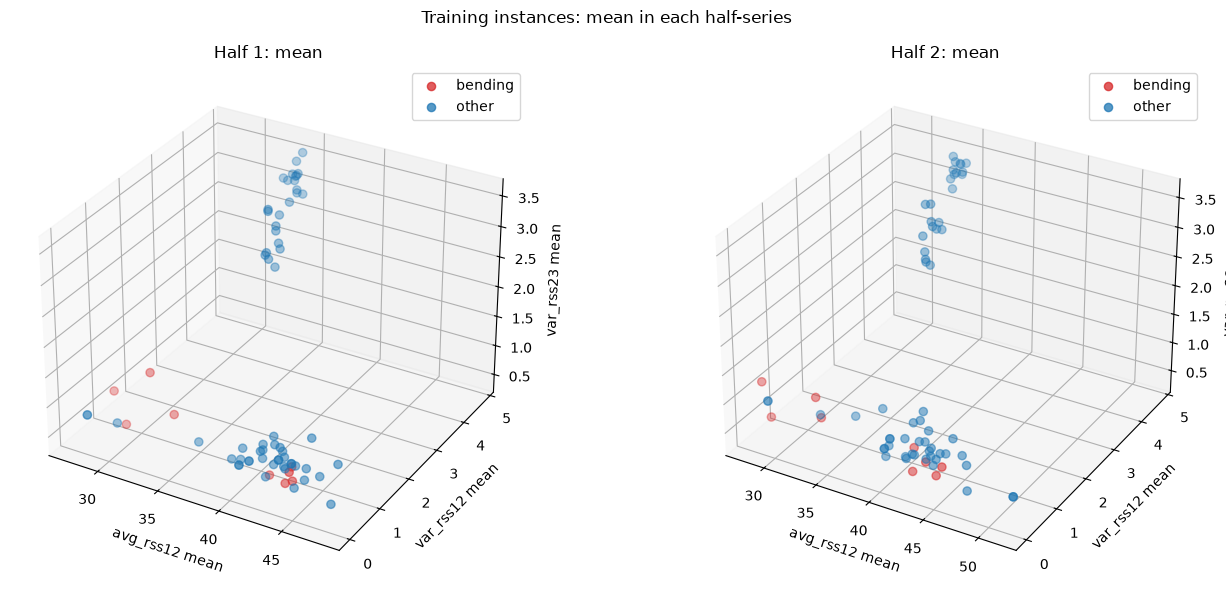

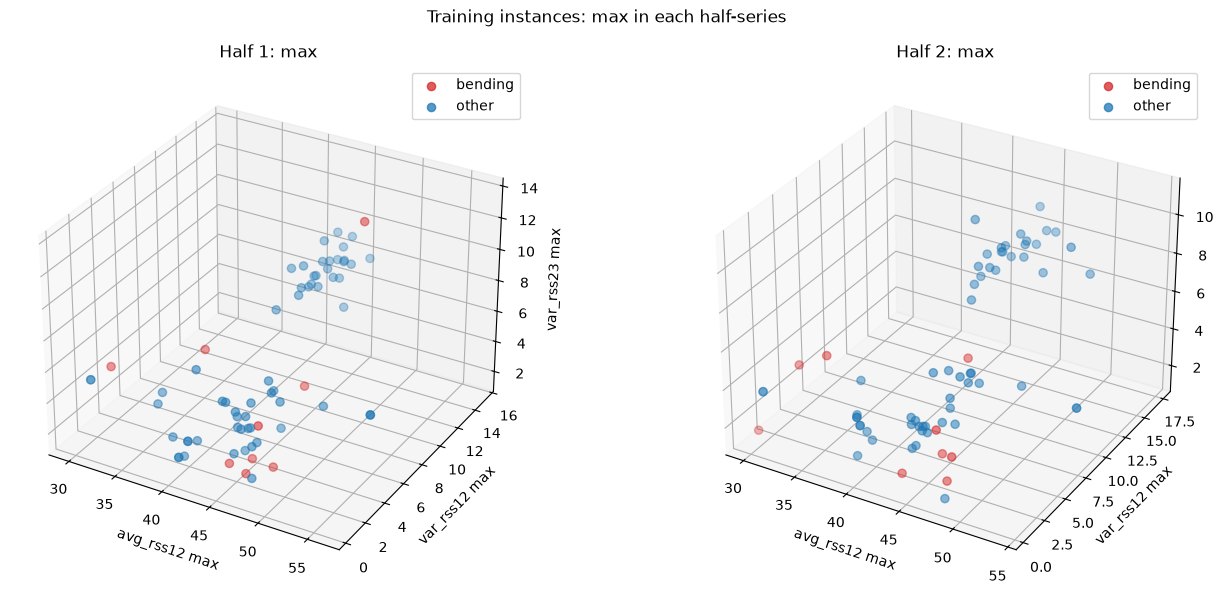

window,full,half 1,half 2
statistic,,,
max,0.862,0.741,1.685
mean,1.584,1.494,1.654
min,0.184,0.342,0.464


In [8]:
half_train = get_segment_frames(2)[0].copy()
half_train["is_bending"] = half_train["activity"].isin(["bending1", "bending2"]).astype(int)

for statistic in selected_statistics:
    fig = plt.figure(figsize=(14, 6))
    for half_index in (1, 2):
        columns = [f"{sensor}_{statistic}_seg{half_index}" for sensor in selected_sensor_names]
        ax = fig.add_subplot(1, 2, half_index, projection="3d")
        for label, color, description in [(1, "tab:red", "bending"), (0, "tab:blue", "other")]:
            subset = half_train.loc[half_train["is_bending"] == label]
            ax.scatter(
                subset[columns[0]], subset[columns[1]], subset[columns[2]],
                color=color, alpha=0.75, s=35, label=description,
            )
        ax.set_xlabel(f"{selected_sensor_names[0]} {statistic}")
        ax.set_ylabel(f"{selected_sensor_names[1]} {statistic}")
        ax.set_zlabel(f"{selected_sensor_names[2]} {statistic}")
        ax.set_title(f"Half {half_index}: {statistic}")
        ax.legend()
    fig.suptitle(f"Training instances: {statistic} in each half-series")
    plt.tight_layout()
    plt.show()

separation_rows = []
for statistic in selected_statistics:
    for segment_index, frame in [("full", binary_train), ("half 1", half_train), ("half 2", half_train)]:
        if segment_index == "full":
            columns = [f"{sensor}_{statistic}_seg1" for sensor in selected_sensor_names]
        else:
            half_number = int(segment_index[-1])
            columns = [f"{sensor}_{statistic}_seg{half_number}" for sensor in selected_sensor_names]
        bending_values = frame.loc[frame["is_bending"] == 1, columns].to_numpy()
        other_values = frame.loc[frame["is_bending"] == 0, columns].to_numpy()
        pooled_sd = np.sqrt((bending_values.var(axis=0, ddof=1) + other_values.var(axis=0, ddof=1)) / 2)
        mean_gap = np.abs(bending_values.mean(axis=0) - other_values.mean(axis=0))
        standardized_gap = np.divide(
            mean_gap, pooled_sd,
            out=np.where(mean_gap > 0, np.inf, 0.0),
            where=pooled_sd > 0,
        )
        separation_rows.append({
            "statistic": statistic,
            "window": segment_index,
            "standardized centroid distance": np.linalg.norm(standardized_gap),
        })
half_series_separation = pd.DataFrame(separation_rows)
display(half_series_separation.pivot(index="statistic", columns="window", values="standardized centroid distance").round(3))

### (a)(iii-vii) Feature selection, evaluation, and class imbalance

For each segment count ℓ = 1, ..., 20, I extract the seven stated summary statistics from all six sensor series (42ℓ candidate columns). I use recursive feature elimination (RFE), the assignment's suggested alternative to backward selection by coefficient p-value, and select both ℓ and the retained feature count *p* by five-fold stratified cross-validation. Scaling and RFE are refit independently inside every fold. The score is balanced accuracy because bending is the minority class. The final training-set model is unpenalized logistic regression (a large *C* approximates no L2 penalty). The correct CV procedure keeps scaling and feature selection inside each training fold. Selecting features once from all training observations before CV would leak information from each validation fold and inflate its score; using the held-out test set to choose ℓ or *p* would also invalidate the final test estimate.

,segments,features_kept,mean_cv_balanced_accuracy,std_cv_balanced_accuracy
0,1,10,0.9833,0.0228
1,3,1,0.9500,0.1118
2,12,10,0.9500,0.1118
3,1,3,0.9417,0.1087
4,7,10,0.9333,0.1046
5,1,2,0.8917,0.1304
6,1,5,0.8917,0.2197
7,2,3,0.8917,0.1304
8,6,5,0.8917,0.1304
9,3,10,0.8750,0.2125


Selected (segments, p): (1, 10)
Selected features: ['avg_rss12_min_seg1', 'avg_rss12_q3_seg1', 'var_rss12_max_seg1', 'avg_rss13_max_seg1', 'var_rss13_max_seg1', 'var_rss13_q1_seg1', 'avg_rss23_min_seg1', 'avg_rss23_max_seg1', 'avg_rss23_mean_seg1', 'var_rss23_q1_seg1']


,parameter,coefficient (standardized predictors),Wald p-value
0,intercept,-16.108741,NaN
1,avg_rss12_min_seg1,-3.244396,NaN
2,avg_rss12_q3_seg1,-3.682325,NaN
3,var_rss12_max_seg1,-3.049218,NaN
4,avg_rss13_max_seg1,-1.697667,NaN
5,var_rss13_max_seg1,3.399108,NaN
6,var_rss13_q1_seg1,-3.209555,NaN
7,avg_rss23_min_seg1,7.812230,NaN
8,avg_rss23_max_seg1,7.890473,NaN
9,avg_rss23_mean_seg1,2.561638,NaN


Perfect separation was detected: unpenalized maximum-likelihood p-values are not identifiable and are reported as NaN.
Training accuracy: 1.0
Training balanced accuracy: 1.0
Training ROC AUC: 1.0
Held-out test accuracy: 1.0
Held-out test balanced accuracy: 1.0
Held-out test ROC AUC: 1.0


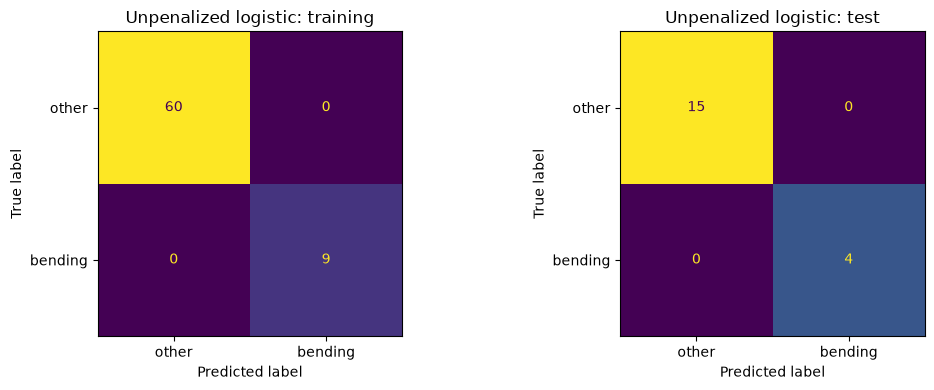

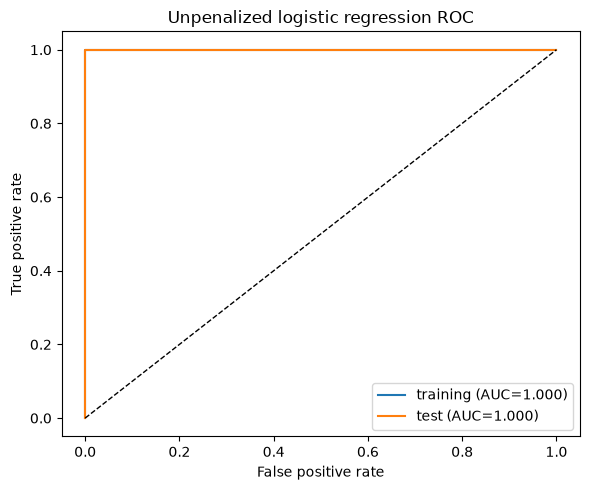

Maximum absolute standardized coefficient: 7.8905
Logistic solver iterations: 12
The GLM detected perfect separation: the classes are well separated in these selected features, and conventional unpenalized logistic coefficients/p-values are unstable.
Training class proportions: is_bending
0    0.869565
1    0.130435
Name: proportion, dtype: float64


In [9]:
binary_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
feature_counts = [1, 2, 3, 5, 10]
logistic_C = 1e6

def make_rfe_pipeline(n_features):
    base_logistic = LogisticRegression(
        C=logistic_C, solver="liblinear", max_iter=10000, random_state=42,
    )
    return Pipeline([
        ("scale", StandardScaler()),
        ("select", RFE(estimator=clone(base_logistic), n_features_to_select=n_features, step=0.5)),
        ("model", clone(base_logistic)),
    ])

rfe_cv_rows = []
for n_segments in range(1, 21):
    train_frame, _ = get_segment_frames(n_segments)
    feature_names = [column for column in train_frame.columns if column not in {"activity", "instance"}]
    X_candidate = train_frame[feature_names]
    y_candidate = train_frame["activity"].isin(["bending1", "bending2"]).astype(int)
    for n_features in feature_counts:
        if n_features >= min(X_candidate.shape[1], len(y_candidate) - 1):
            continue
        estimator = make_rfe_pipeline(n_features)
        fold_scores = cross_val_score(
            estimator, X_candidate, y_candidate, cv=binary_cv,
            scoring="balanced_accuracy", n_jobs=1,
        )
        rfe_cv_rows.append({
            "segments": n_segments,
            "features_kept": n_features,
            "mean_cv_balanced_accuracy": fold_scores.mean(),
            "std_cv_balanced_accuracy": fold_scores.std(ddof=1),
        })

rfe_cv_results = pd.DataFrame(rfe_cv_rows).sort_values(
    ["mean_cv_balanced_accuracy", "segments", "features_kept"],
    ascending=[False, True, True],
).reset_index(drop=True)
display(rfe_cv_results.head(10).round(4))
best_rfe = rfe_cv_results.iloc[0]
best_rfe_l = int(best_rfe["segments"])
best_rfe_p = int(best_rfe["features_kept"])
print(f"Selected (segments, p): ({best_rfe_l}, {best_rfe_p})")

X_a_train = get_segment_frames(best_rfe_l)[0]
X_a_train = X_a_train.drop(columns=["activity", "instance"])
y_a_train = binary_train["is_bending"].reset_index(drop=True)
a_model = make_rfe_pipeline(best_rfe_p)
a_model.fit(X_a_train, y_a_train)
a_selected_features = X_a_train.columns[a_model.named_steps["select"].support_].tolist()
print("Selected features:", a_selected_features)

# Wald p-values are descriptive post-selection estimates for the final reduced model.
X_a_scaled = a_model.named_steps["scale"].transform(X_a_train)
X_a_selected = X_a_scaled[:, a_model.named_steps["select"].support_]
with warnings.catch_warnings(record=True) as glm_warnings:
    warnings.simplefilter("always", PerfectSeparationWarning)
    glm_result = sm.GLM(
        y_a_train.to_numpy(), sm.add_constant(X_a_selected, has_constant="add"),
        family=sm.families.Binomial(),
    ).fit(maxiter=200)
separation_detected = any(
    issubclass(warning.category, PerfectSeparationWarning)
    for warning in glm_warnings
)
reported_parameters = (
    np.concatenate([a_model.named_steps["model"].intercept_, a_model.named_steps["model"].coef_[0]])
    if separation_detected else glm_result.params
)
a_parameter_table = pd.DataFrame({
    "parameter": ["intercept", *a_selected_features],
    "coefficient (standardized predictors)": reported_parameters,
    "Wald p-value": (
        np.full(len(glm_result.params), np.nan) if separation_detected else glm_result.pvalues
    ),
})
display(a_parameter_table.round(6))
if separation_detected:
    print("Perfect separation was detected: unpenalized maximum-likelihood p-values are not identifiable and are reported as NaN.")
else:
    print("These p-values are post-selection and descriptive, not confirmatory inference.")

X_a_test = get_segment_frames(best_rfe_l)[1].drop(columns=["activity", "instance"])
y_a_test = get_segment_frames(best_rfe_l)[1]["activity"].isin(["bending1", "bending2"]).astype(int)
a_train_probability = a_model.predict_proba(X_a_train)[:, 1]
a_test_probability = a_model.predict_proba(X_a_test)[:, 1]
a_train_prediction = (a_train_probability >= 0.5).astype(int)
a_test_prediction = (a_test_probability >= 0.5).astype(int)
print("Training accuracy:", round(accuracy_score(y_a_train, a_train_prediction), 4))
print("Training balanced accuracy:", round(balanced_accuracy_score(y_a_train, a_train_prediction), 4))
print("Training ROC AUC:", round(roc_auc_score(y_a_train, a_train_probability), 4))
print("Held-out test accuracy:", round(accuracy_score(y_a_test, a_test_prediction), 4))
print("Held-out test balanced accuracy:", round(balanced_accuracy_score(y_a_test, a_test_prediction), 4))
print("Held-out test ROC AUC:", round(roc_auc_score(y_a_test, a_test_probability), 4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_a_train, a_train_prediction, display_labels=["other", "bending"],
    colorbar=False, ax=axes[0],
)
axes[0].set_title("Unpenalized logistic: training")
ConfusionMatrixDisplay.from_predictions(
    y_a_test, a_test_prediction, display_labels=["other", "bending"],
    colorbar=False, ax=axes[1],
)
axes[1].set_title("Unpenalized logistic: test")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for truth, probability, label in [
    (y_a_train, a_train_probability, "training"),
    (y_a_test, a_test_probability, "test"),
]:
    fpr, tpr, _ = roc_curve(truth, probability)
    ax.plot(fpr, tpr, label=f"{label} (AUC={roc_auc_score(truth, probability):.3f})")
ax.plot([0, 1], [0, 1], "k--", linewidth=1)
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="Unpenalized logistic regression ROC")
ax.legend()
plt.tight_layout()
plt.show()

max_abs_coefficient = np.abs(a_model.named_steps["model"].coef_).max()
print("Maximum absolute standardized coefficient:", round(float(max_abs_coefficient), 4))
print("Logistic solver iterations:", int(a_model.named_steps["model"].n_iter_[0]))
if separation_detected:
    print("The GLM detected perfect separation: the classes are well separated in these selected features, and conventional unpenalized logistic coefficients/p-values are unstable.")
elif max_abs_coefficient > 10:
    print("The very large standardized coefficient is evidence consistent with near-separation; Wald inference may be unstable.")
else:
    print("There is no extreme standardized coefficient in this fit; the coefficient size alone does not indicate severe separation.")
print("Training class proportions:", y_a_train.value_counts(normalize=True).sort_index())

The training confusion matrix and class proportions above address class imbalance. As a case-control alternative, I retain every bending instance, randomly downsample the other-activity controls to the same count, fit the selected logistic model, and correct its intercept to the original training prevalence. The correction is logit(prevalence in the full training set) minus logit(prevalence in the case-control sample); this changes probability calibration without changing slopes.

,split,accuracy,balanced accuracy,ROC AUC
0,training,1.0,1.0,1.0
1,test,1.0,1.0,1.0


Intercept adjustment: -1.8971


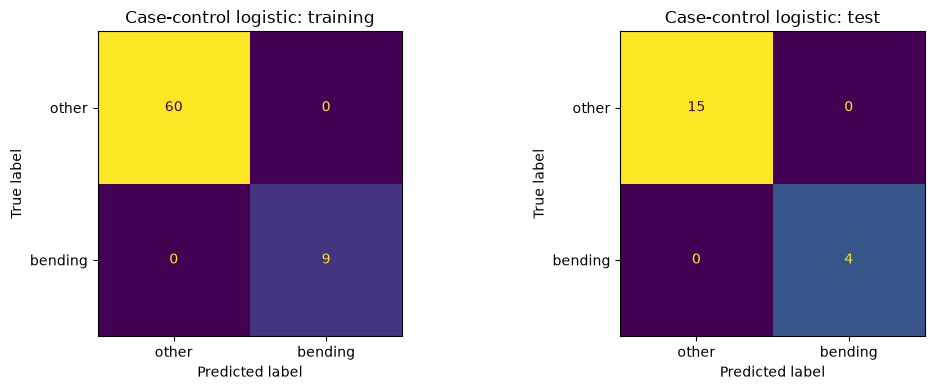

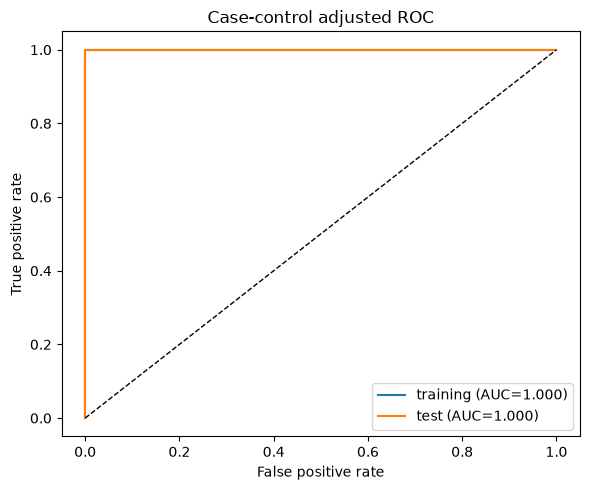

In [10]:
a_scaler = StandardScaler().fit(X_a_train)
X_a_train_scaled = a_scaler.transform(X_a_train)
X_a_test_scaled = a_scaler.transform(X_a_test)
selected_indices = [X_a_train.columns.get_loc(name) for name in a_selected_features]
positive_indices = np.flatnonzero(y_a_train.to_numpy() == 1)
negative_indices = np.flatnonzero(y_a_train.to_numpy() == 0)
case_control_rng = np.random.default_rng(42)
sampled_negative_indices = case_control_rng.choice(
    negative_indices, size=len(positive_indices), replace=False,
)
case_control_indices = np.concatenate([positive_indices, sampled_negative_indices])
case_control_model = LogisticRegression(
    C=logistic_C, solver="liblinear", max_iter=10000, random_state=42,
)
case_control_model.fit(
    X_a_train_scaled[case_control_indices][:, selected_indices],
    y_a_train.to_numpy()[case_control_indices],
)
full_prevalence = y_a_train.mean()
sample_prevalence = y_a_train.to_numpy()[case_control_indices].mean()
intercept_adjustment = (
    np.log(full_prevalence / (1 - full_prevalence))
    - np.log(sample_prevalence / (1 - sample_prevalence))
)
adjusted_intercept = case_control_model.intercept_[0] + intercept_adjustment

def case_control_probability(X_scaled):
    linear_predictor = (
        X_scaled[:, selected_indices] @ case_control_model.coef_[0]
        + adjusted_intercept
    )
    return expit(linear_predictor)

case_control_train_probability = case_control_probability(X_a_train_scaled)
case_control_test_probability = case_control_probability(X_a_test_scaled)
case_control_train_prediction = (case_control_train_probability >= 0.5).astype(int)
case_control_test_prediction = (case_control_test_probability >= 0.5).astype(int)
case_control_metrics = pd.DataFrame([
    {
        "split": "training",
        "accuracy": accuracy_score(y_a_train, case_control_train_prediction),
        "balanced accuracy": balanced_accuracy_score(y_a_train, case_control_train_prediction),
        "ROC AUC": roc_auc_score(y_a_train, case_control_train_probability),
    },
    {
        "split": "test",
        "accuracy": accuracy_score(y_a_test, case_control_test_prediction),
        "balanced accuracy": balanced_accuracy_score(y_a_test, case_control_test_prediction),
        "ROC AUC": roc_auc_score(y_a_test, case_control_test_probability),
    },
])
display(case_control_metrics.round(4))
print("Intercept adjustment:", round(float(intercept_adjustment), 4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_a_train, case_control_train_prediction, display_labels=["other", "bending"],
    colorbar=False, ax=axes[0],
)
axes[0].set_title("Case-control logistic: training")
ConfusionMatrixDisplay.from_predictions(
    y_a_test, case_control_test_prediction, display_labels=["other", "bending"],
    colorbar=False, ax=axes[1],
)
axes[1].set_title("Case-control logistic: test")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for truth, probability, label in [
    (y_a_train, case_control_train_probability, "training"),
    (y_a_test, case_control_test_probability, "test"),
]:
    fpr, tpr, _ = roc_curve(truth, probability)
    ax.plot(fpr, tpr, label=f"{label} (AUC={roc_auc_score(truth, probability):.3f})")
ax.plot([0, 1], [0, 1], "k--", linewidth=1)
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="Case-control adjusted ROC")
ax.legend()
plt.tight_layout()
plt.show()

### (b) L1-penalized binary logistic regression

I repeat the segment-count search, now jointly tuning the number of segments ℓ and inverse L1 penalty strength *C* (larger *C* means weaker shrinkage). Standardization is inside the cross-validation pipeline. This gives a sparse model without a separate p-value/RFE feature-count search.

,segments,C,mean_cv_balanced_accuracy,std_cv_balanced_accuracy
0,2,10.0,0.9417,0.1087
1,10,100.0,0.9417,0.1087
2,12,1.0,0.9417,0.1087
3,12,10.0,0.9417,0.1087
4,20,100.0,0.9417,0.1087
5,1,10.0,0.9333,0.1046
6,1,100.0,0.9333,0.1046
7,6,10.0,0.9333,0.1046
8,6,100.0,0.9333,0.1046
9,12,100.0,0.9333,0.1046


Selected (segments, C): (2, 10)


,split,accuracy,balanced accuracy,ROC AUC
0,training,1.0000,1.000,1.0
1,test,0.9474,0.875,1.0


Nonzero coefficients: 10 of 84


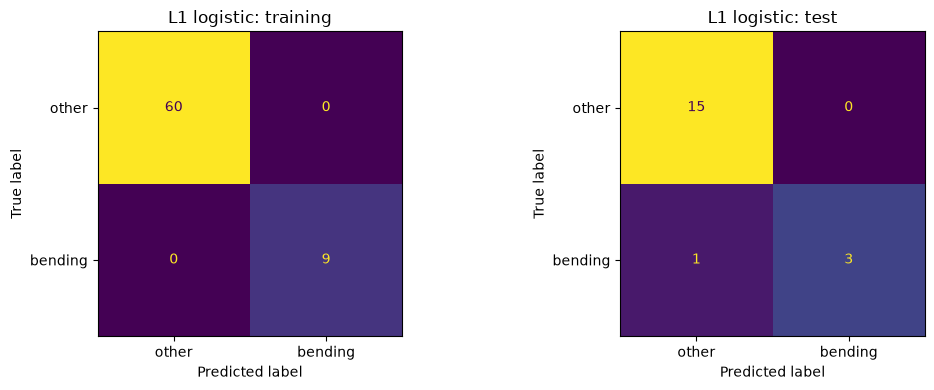

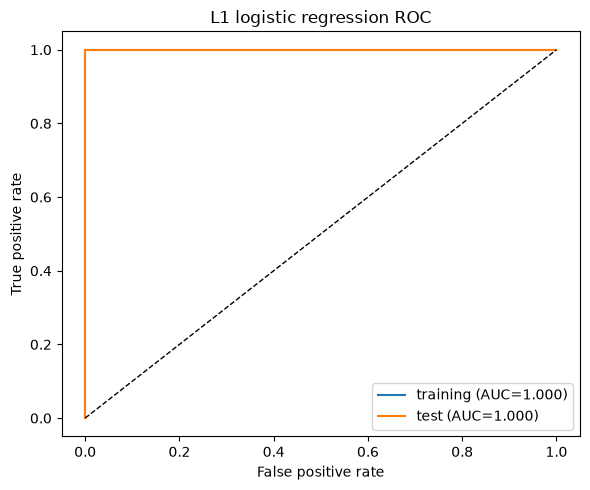

Unpenalized RFE best CV balanced accuracy: 0.9833
L1 best CV balanced accuracy: 0.9417
Unpenalized RFE test balanced accuracy: 1.0
L1 logistic test balanced accuracy: 0.875
For this split, the higher cross-validation and test balanced accuracies identify the better-performing selection approach; L1 is simpler to implement and returns a sparse model, while RFE explicitly selects a feature count.
The L1-selected segment count (2) matches the two-half plots above when it equals 2.


In [11]:
l1_C_values = [0.001, 0.01, 0.1, 1, 10, 100]
l1_cv_rows = []
for n_segments in range(1, 21):
    train_frame, _ = get_segment_frames(n_segments)
    feature_names = [column for column in train_frame.columns if column not in {"activity", "instance"}]
    X_candidate = train_frame[feature_names]
    y_candidate = train_frame["activity"].isin(["bending1", "bending2"]).astype(int)
    for C in l1_C_values:
        estimator = Pipeline([
            ("scale", StandardScaler()),
            ("model", LogisticRegression(
                l1_ratio=1, C=C, solver="liblinear", max_iter=10000, random_state=42,
            )),
        ])
        fold_scores = cross_val_score(
            estimator, X_candidate, y_candidate, cv=binary_cv,
            scoring="balanced_accuracy", n_jobs=1,
        )
        l1_cv_rows.append({
            "segments": n_segments,
            "C": C,
            "mean_cv_balanced_accuracy": fold_scores.mean(),
            "std_cv_balanced_accuracy": fold_scores.std(ddof=1),
        })

l1_cv_results = pd.DataFrame(l1_cv_rows).sort_values(
    ["mean_cv_balanced_accuracy", "segments", "C"],
    ascending=[False, True, True],
).reset_index(drop=True)
display(l1_cv_results.head(10).round(4))
best_l1 = l1_cv_results.iloc[0]
best_l1_l = int(best_l1["segments"])
best_l1_C = float(best_l1["C"])
print(f"Selected (segments, C): ({best_l1_l}, {best_l1_C:g})")

X_l1_train_frame, X_l1_test_frame = get_segment_frames(best_l1_l)
X_l1_train = X_l1_train_frame.drop(columns=["activity", "instance"])
X_l1_test = X_l1_test_frame.drop(columns=["activity", "instance"])
y_l1_train = X_l1_train_frame["activity"].isin(["bending1", "bending2"]).astype(int)
y_l1_test = X_l1_test_frame["activity"].isin(["bending1", "bending2"]).astype(int)
l1_binary_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(
        l1_ratio=1, C=best_l1_C, solver="liblinear", max_iter=10000, random_state=42,
    )),
])
l1_binary_model.fit(X_l1_train, y_l1_train)
l1_nonzero = int(np.count_nonzero(l1_binary_model.named_steps["model"].coef_))
l1_train_probability = l1_binary_model.predict_proba(X_l1_train)[:, 1]
l1_test_probability = l1_binary_model.predict_proba(X_l1_test)[:, 1]
l1_train_prediction = (l1_train_probability >= 0.5).astype(int)
l1_test_prediction = (l1_test_probability >= 0.5).astype(int)
l1_binary_metrics = pd.DataFrame([
    {
        "split": "training", "accuracy": accuracy_score(y_l1_train, l1_train_prediction),
        "balanced accuracy": balanced_accuracy_score(y_l1_train, l1_train_prediction),
        "ROC AUC": roc_auc_score(y_l1_train, l1_train_probability),
    },
    {
        "split": "test", "accuracy": accuracy_score(y_l1_test, l1_test_prediction),
        "balanced accuracy": balanced_accuracy_score(y_l1_test, l1_test_prediction),
        "ROC AUC": roc_auc_score(y_l1_test, l1_test_probability),
    },
])
display(l1_binary_metrics.round(4))
print(f"Nonzero coefficients: {l1_nonzero} of {X_l1_train.shape[1]}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_l1_train, l1_train_prediction, display_labels=["other", "bending"],
    colorbar=False, ax=axes[0],
)
axes[0].set_title("L1 logistic: training")
ConfusionMatrixDisplay.from_predictions(
    y_l1_test, l1_test_prediction, display_labels=["other", "bending"],
    colorbar=False, ax=axes[1],
)
axes[1].set_title("L1 logistic: test")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for truth, probability, label in [
    (y_l1_train, l1_train_probability, "training"),
    (y_l1_test, l1_test_probability, "test"),
]:
    fpr, tpr, _ = roc_curve(truth, probability)
    ax.plot(fpr, tpr, label=f"{label} (AUC={roc_auc_score(truth, probability):.3f})")
ax.plot([0, 1], [0, 1], "k--", linewidth=1)
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="L1 logistic regression ROC")
ax.legend()
plt.tight_layout()
plt.show()

print("Unpenalized RFE best CV balanced accuracy:", round(float(best_rfe["mean_cv_balanced_accuracy"]), 4))
print("L1 best CV balanced accuracy:", round(float(best_l1["mean_cv_balanced_accuracy"]), 4))
print("Unpenalized RFE test balanced accuracy:", round(balanced_accuracy_score(y_a_test, a_test_prediction), 4))
print("L1 logistic test balanced accuracy:", round(balanced_accuracy_score(y_l1_test, l1_test_prediction), 4))
print("For this split, the higher cross-validation and test balanced accuracies identify the better-performing selection approach; L1 is simpler to implement and returns a sparse model, while RFE explicitly selects a feature count.")
print(f"The L1-selected segment count ({best_l1_l}) matches the two-half plots above when it equals 2.")

## (c) Multiclass classification

The multiclass models use all seven activities. The number of segments is selected by the binary L1 cross-validation search in part (b), as specified in the prompt. Multiclass L1 logistic regression selects *C* by four-fold stratified cross-validation: the least-represented training class has four examples, so five folds cannot include that class in every validation fold. Four folds allow each validation split to contain every class. Multiclass ROC curves are one-versus-rest curves; the reported AUC is macro-averaged over the seven classes.

,C,mean_cv_balanced_accuracy,std_cv_balanced_accuracy
0,100.000,0.8333,0.0615
1,10.000,0.8214,0.1190
2,1.000,0.7917,0.1596
3,0.100,0.5238,0.0389
4,0.001,0.1429,0.0000
5,0.010,0.1429,0.0000


Using segments=2; selected multiclass C=100


L1 multinomial logistic regression classification report:
              precision    recall  f1-score   support

    bending1       0.67      1.00      0.80         2
    bending2       1.00      0.50      0.67         2
     cycling       1.00      1.00      1.00         3
       lying       1.00      1.00      1.00         3
     sitting       0.50      0.33      0.40         3
    standing       0.75      1.00      0.86         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.84        19
   macro avg       0.85      0.83      0.82        19
weighted avg       0.85      0.84      0.83        19



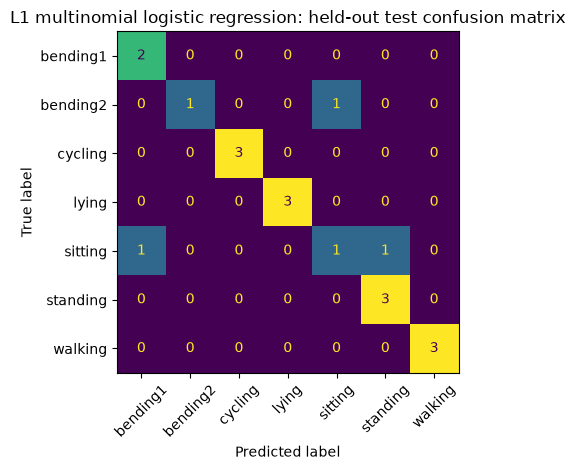

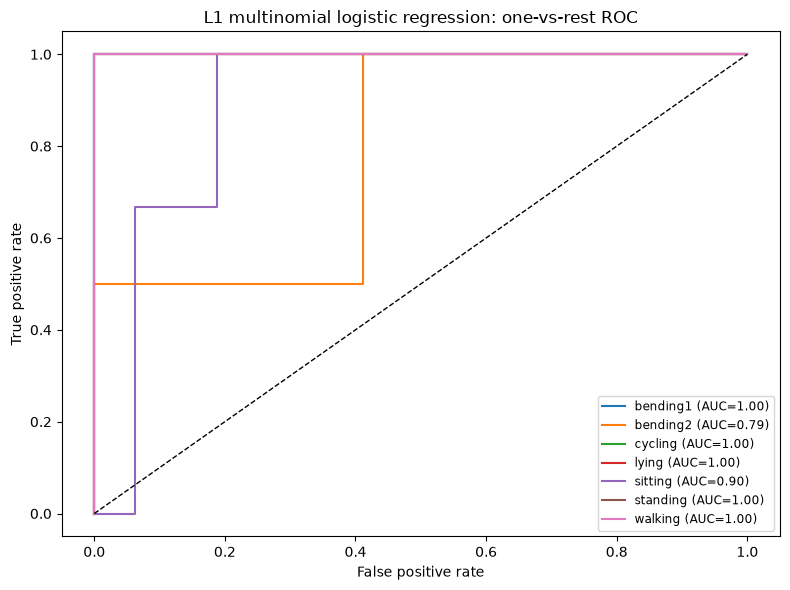

Multiclass L1 nonzero coefficients: 394


In [12]:
multiclass_train_frame, multiclass_test_frame = get_segment_frames(best_l1_l)
X_multi_train = multiclass_train_frame.drop(columns=["activity", "instance"])
y_multi_train = multiclass_train_frame["activity"].reset_index(drop=True)
X_multi_test = multiclass_test_frame.drop(columns=["activity", "instance"])
y_multi_test = multiclass_test_frame["activity"].reset_index(drop=True)

multiclass_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
multiclass_cv_rows = []
for C in l1_C_values:
    estimator = Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(
            l1_ratio=1, C=C, solver="saga", max_iter=30000, random_state=42,
        )),
    ])
    fold_scores = cross_val_score(
        estimator, X_multi_train, y_multi_train, cv=multiclass_cv,
        scoring="balanced_accuracy", n_jobs=1,
    )
    multiclass_cv_rows.append({
        "C": C,
        "mean_cv_balanced_accuracy": fold_scores.mean(),
        "std_cv_balanced_accuracy": fold_scores.std(ddof=1),
    })
multiclass_cv_results = pd.DataFrame(multiclass_cv_rows).sort_values(
    ["mean_cv_balanced_accuracy", "C"], ascending=[False, True],
).reset_index(drop=True)
display(multiclass_cv_results.round(4))
best_multiclass_C = float(multiclass_cv_results.iloc[0]["C"])
print(f"Using segments={best_l1_l}; selected multiclass C={best_multiclass_C:g}")

multiclass_l1_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(
        l1_ratio=1, C=best_multiclass_C, solver="saga", max_iter=30000, random_state=42,
    )),
])
multiclass_l1_model.fit(X_multi_train, y_multi_train)

def evaluate_multiclass(model, X_test, y_test, model_name):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)
    classes = model.named_steps["model"].classes_
    encoded_truth = label_binarize(y_test, classes=classes)
    auc = roc_auc_score(encoded_truth, probabilities, average="macro", multi_class="ovr")
    metrics = {
        "model": model_name,
        "test error": 1 - accuracy_score(y_test, predictions),
        "accuracy": accuracy_score(y_test, predictions),
        "balanced accuracy": balanced_accuracy_score(y_test, predictions),
        "macro one-vs-rest AUC": auc,
    }
    print(model_name, "classification report:")
    print(classification_report(y_test, predictions, labels=classes, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, labels=classes, display_labels=classes,
        xticks_rotation=45, colorbar=False,
    )
    plt.title(f"{model_name}: held-out test confusion matrix")
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 6))
    for index, class_name in enumerate(classes):
        fpr, tpr, _ = roc_curve(encoded_truth[:, index], probabilities[:, index])
        class_auc = roc_auc_score(encoded_truth[:, index], probabilities[:, index])
        ax.plot(fpr, tpr, label=f"{class_name} (AUC={class_auc:.2f})")
    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    ax.set(xlabel="False positive rate", ylabel="True positive rate", title=f"{model_name}: one-vs-rest ROC")
    ax.legend(loc="lower right", fontsize="small")
    plt.tight_layout()
    plt.show()
    return metrics

multiclass_l1_metrics = evaluate_multiclass(
    multiclass_l1_model, X_multi_test, y_multi_test, "L1 multinomial logistic regression",
)
print("Multiclass L1 nonzero coefficients:", int(np.count_nonzero(multiclass_l1_model.named_steps["model"].coef_)))

### (c)(ii-iii) Gaussian and multinomial Naive Bayes; comparison

Gaussian Naive Bayes accepts real-valued summary features. Multinomial Naive Bayes requires nonnegative input, so its pipeline scales each feature to [0, 1] using training-fold/training-set minima and maxima. I compare test error, balanced accuracy, and macro one-versus-rest AUC; on this small held-out set, those estimates have substantial sampling uncertainty.

Gaussian Naive Bayes

 classification report:
              precision    recall  f1-score   support

    bending1       0.00      0.00      0.00         2
    bending2       0.00      0.00      0.00         2
     cycling       1.00      1.00      1.00         3
       lying       0.43      1.00      0.60         3
     sitting       0.33      0.33      0.33         3
    standing       0.67      0.67      0.67         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.63        19
   macro avg       0.49      0.57      0.51        19
weighted avg       0.54      0.63      0.57        19



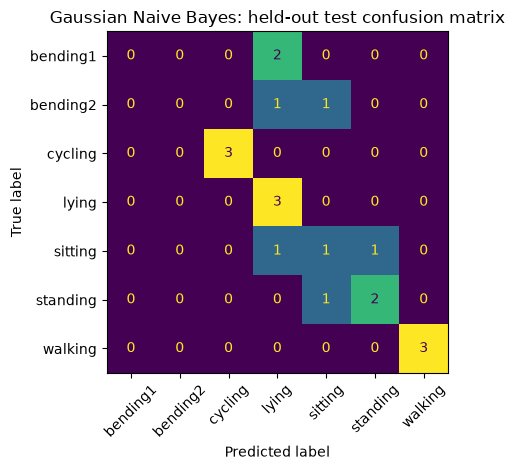

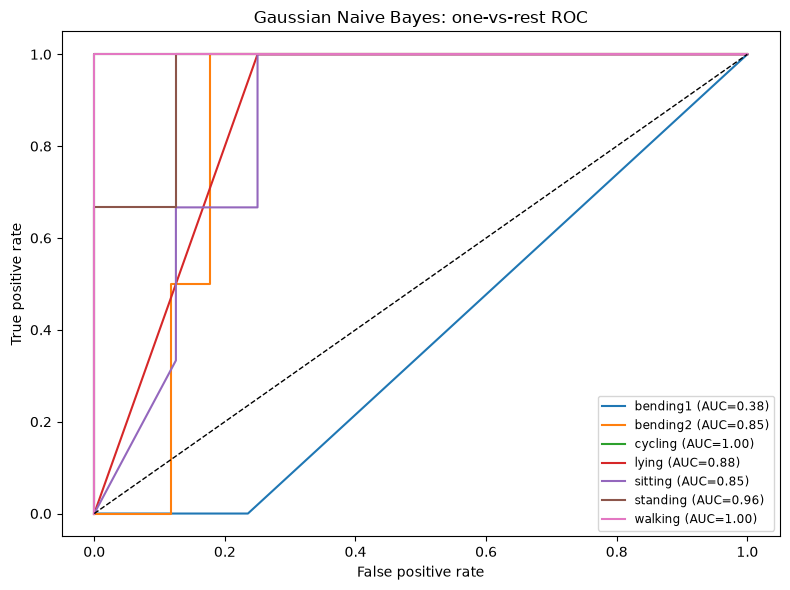

Multinomial Naive Bayes classification report:
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      0.50      0.67         2
     cycling       0.75      1.00      0.86         3
       lying       1.00      0.67      0.80         3
     sitting       0.50      0.67      0.57         3
    standing       0.67      0.67      0.67         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.79        19
   macro avg       0.85      0.79      0.79        19
weighted avg       0.83      0.79      0.79        19



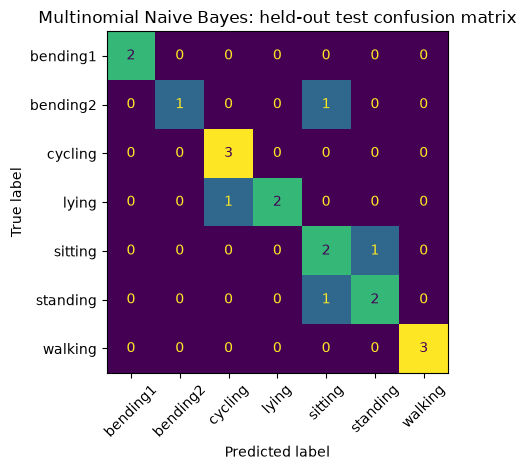

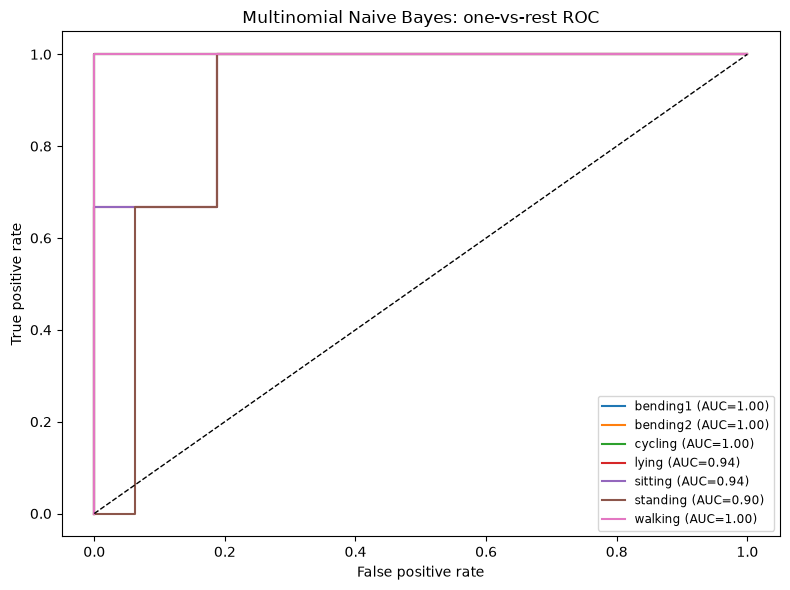

,model,test error,accuracy,balanced accuracy,macro one-vs-rest AUC
0,L1 multinomial logistic regression,0.1579,0.8421,0.8333,0.9557
1,Multinomial Naive Bayes,0.2105,0.7895,0.7857,0.9673
2,Gaussian Naive Bayes,0.3684,0.6316,0.5714,0.8461


Best by test balanced accuracy: L1 multinomial logistic regression
Best by test macro one-vs-rest AUC: Multinomial Naive Bayes
The preferred method depends on whether class-wise accuracy or probability ranking is the priority; the small test set makes these comparisons uncertain.
Naive Bayes is easier to fit, but its conditional-independence assumption is restrictive for correlated sensor summaries. Regularized multinomial logistic regression models class boundaries jointly and can use L1 to select a sparse set of coefficients.


In [13]:
gaussian_nb_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", GaussianNB()),
])
gaussian_nb_model.fit(X_multi_train, y_multi_train)
gaussian_nb_metrics = evaluate_multiclass(
    gaussian_nb_model, X_multi_test, y_multi_test, "Gaussian Naive Bayes",
)

multinomial_nb_model = Pipeline([
    ("scale", MinMaxScaler()),
    ("model", MultinomialNB()),
])
multinomial_nb_model.fit(X_multi_train, y_multi_train)
multinomial_nb_metrics = evaluate_multiclass(
    multinomial_nb_model, X_multi_test, y_multi_test, "Multinomial Naive Bayes",
)

multiclass_comparison = pd.DataFrame([
    multiclass_l1_metrics,
    gaussian_nb_metrics,
    multinomial_nb_metrics,
]).sort_values(
    ["balanced accuracy", "macro one-vs-rest AUC"], ascending=False,
).reset_index(drop=True)
display(multiclass_comparison.round(4))
best_by_auc = multiclass_comparison.sort_values("macro one-vs-rest AUC", ascending=False).iloc[0]
print("Best by test balanced accuracy:", multiclass_comparison.iloc[0]["model"])
print("Best by test macro one-vs-rest AUC:", best_by_auc["model"])
print("The preferred method depends on whether class-wise accuracy or probability ranking is the priority; the small test set makes these comparisons uncertain.")
print("Naive Bayes is easier to fit, but its conditional-independence assumption is restrictive for correlated sensor summaries. Regularized multinomial logistic regression models class boundaries jointly and can use L1 to select a sparse set of coefficients.")